# 实验6 利用sklearn进行数据预处理
依据课程要求与教材例题运行。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn import preprocessing
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display
%matplotlib inline
np.set_printoptions(precision=6, suppress=True)
plt.rcParams['figure.figsize'] = (6, 3)
print('numpy', np.__version__, 'pandas', pd.__version__)
print('sklearn', sklearn.__version__)


numpy 2.3.5 pandas 2.3.3
sklearn 1.9.0


In [2]:
# 例3-41 按特征标准化并求均值和标准差
X_train = np.array([[1., -2., 1.5], [2.2, 1.3, 0.5],
                    [0.3, 1., -1.5]])
X41 = preprocessing.scale(X_train)
print('原始训练数据：'); print(X_train)
print('标准化结果：'); print(X41)
print('各列均值：', X41.mean(axis=0))
print('各列标准差：', X41.std(axis=0))

原始训练数据：
[[ 1.  -2.   1.5]
 [ 2.2  1.3  0.5]
 [ 0.3  1.  -1.5]]
标准化结果：
[[-0.21243  -1.409428  1.069045]
 [ 1.317064  0.805387  0.267261]
 [-1.104634  0.60404  -1.336306]]
各列均值： [0. 0. 0.]
各列标准差： [1. 1. 1.]


In [3]:
# 例3-42 拟合StandardScaler并用于测试数据
scaler = preprocessing.StandardScaler().fit(X_train)
print('scale_：', scaler.scale_)
print('mean_：', scaler.mean_)
X42 = scaler.transform(X_train)
print('训练集标准化结果：'); print(X42)
X_test42 = np.array([[-1., 1., 0.]])
print('测试集标准化结果：')
print(scaler.transform(X_test42))

scale_： [0.784573 1.489966 1.247219]
mean_： [1.166667 0.1      0.166667]
训练集标准化结果：
[[-0.21243  -1.409428  1.069045]
 [ 1.317064  0.805387  0.267261]
 [-1.104634  0.60404  -1.336306]]
测试集标准化结果：
[[-2.761585  0.60404  -0.133631]]


In [4]:
# 例3-43 将训练数据按列缩放到0至1
X_train43 = np.array([[1., -1., 2.], [2., 0., 0.],
                      [0., 1., -1.]])
min_max_scaler = preprocessing.MinMaxScaler()
X43 = min_max_scaler.fit_transform(X_train43)
print('原始数据：'); print(X_train43)
print('训练集缩放结果：'); print(X43)
X_test43 = np.array([[-3., -1., 4.]])
print('测试集缩放结果：')
print(min_max_scaler.transform(X_test43))
print('scale_：', min_max_scaler.scale_)
print('min_：', min_max_scaler.min_)

原始数据：
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]
训练集缩放结果：
[[0.5      0.       1.      ]
 [1.       0.5      0.333333]
 [0.       1.       0.      ]]
测试集缩放结果：
[[-1.5       0.        1.666667]]
scale_： [0.5      0.5      0.333333]
min_： [0.       0.5      0.333333]


In [5]:
# 例3-44 按每列最大绝对值缩放
max_abs_scaler = preprocessing.MaxAbsScaler()
X44 = max_abs_scaler.fit_transform(X_train43)
print('原始数据：'); print(X_train43)
print('训练集归一化结果：'); print(X44)
print('各列最大绝对值：', max_abs_scaler.scale_)
print('测试集归一化结果：')
print(max_abs_scaler.transform(X_test43))

原始数据：
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]
训练集归一化结果：
[[ 0.5 -1.   1. ]
 [ 1.   0.   0. ]
 [ 0.   1.  -0.5]]
各列最大绝对值： [2. 1. 2.]
测试集归一化结果：
[[-1.5 -1.   2. ]]


In [6]:
# 例3-45 鸢尾花特征映射到0至1均匀分布
X, y = load_iris(return_X_y=True)
X_train45, X_test45, y_train, y_test = train_test_split(
    X, y, random_state=0)
qt45 = preprocessing.QuantileTransformer(
    n_quantiles=len(X_train45), random_state=0)
X45 = qt45.fit_transform(X_train45)
X_test45_trans = qt45.transform(X_test45)
print('训练集、测试集形状：', X45.shape,
      X_test45_trans.shape)
q = [0, 25, 50, 75, 100]
print('萼片长度原始分位数：')
print(np.percentile(X_train45[:, 0], q))
print('变换后的分位数：')
print(np.percentile(X45[:, 0], q))

训练集、测试集形状： (112, 4) (38, 4)
萼片长度原始分位数：
[4.3 5.1 5.8 6.5 7.9]
变换后的分位数：
[0.       0.238739 0.509009 0.743243 1.      ]


In [7]:
# 例3-46 Box-Cox变换教材样本
pt = preprocessing.PowerTransformer(
    method='box-cox', standardize=False)
X_lognormal = np.random.RandomState(616).lognormal(
    size=(3, 3))
T46 = pt.fit_transform(X_lognormal)
print('对数正态样本：'); print(X_lognormal)
print('Box-Cox变换结果：'); print(T46)
print('每列lambda：', pt.lambdas_)

对数正态样本：
[[1.283317 1.180922 0.841603]
 [0.942933 1.609608 0.38791 ]
 [1.352357 0.217157 1.099771]]
Box-Cox变换结果：
[[ 0.490243  0.17882  -0.156378]
 [-0.051029  0.588632 -0.576124]
 [ 0.6942   -0.848578  0.100515]]
每列lambda： [4.920118 0.862966 1.153544]


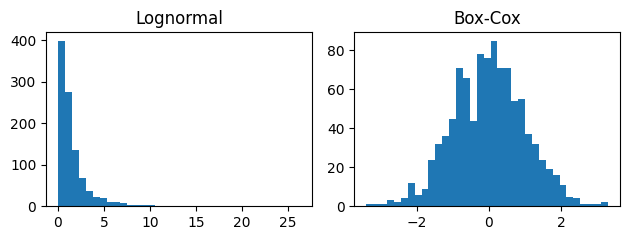

In [8]:
# 例3-46 用较多样本观察变换前后分布
sample46 = np.random.RandomState(616).lognormal(
    size=(1000, 1))
pt_plot = preprocessing.PowerTransformer(method='box-cox')
normal46 = pt_plot.fit_transform(sample46)
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5))
axes[0].hist(sample46.ravel(), bins=35)
axes[0].set_title('Lognormal')
axes[1].hist(normal46.ravel(), bins=35)
axes[1].set_title('Box-Cox')
plt.tight_layout(); plt.show()

In [9]:
# 例3-47 映射到近似高斯分布
X, y = load_iris(return_X_y=True)
qt47 = preprocessing.QuantileTransformer(
    n_quantiles=len(X), output_distribution='normal',
    random_state=0)
X47 = qt47.fit_transform(X)
print('学习到的前6个分位点：')
print(qt47.quantiles_[:6])
print('变换后前5个样本：'); print(X47[:5])
print('变换结果形状：', X47.shape)

学习到的前6个分位点：
[[4.3 2.  1.  0.1]
 [4.4 2.2 1.1 0.1]
 [4.4 2.2 1.2 0.1]
 [4.4 2.2 1.2 0.1]
 [4.5 2.3 1.3 0.1]
 [4.6 2.3 1.3 0.2]]
变换后前5个样本：
[[-0.701131  1.061219 -1.20504  -1.138208]
 [-1.154434 -0.084214 -1.20504  -1.138208]
 [-1.523968  0.443066 -1.67487  -1.138208]
 [-1.710095  0.229099 -0.836836 -1.138208]
 [-0.923581  1.222611 -1.20504  -1.138208]]
变换结果形状： (150, 4)


In [10]:
# 例3-48 按样本进行L2正则化
X = np.array([[1., -1., 2.], [2., 0., 0.],
              [0., 1., -1.]])
X48 = preprocessing.normalize(X, norm='l2')
print('正则化结果：'); print(X48)
print('每行L2范数：', np.linalg.norm(X48, axis=1))

正则化结果：
[[ 0.408248 -0.408248  0.816497]
 [ 1.        0.        0.      ]
 [ 0.        0.707107 -0.707107]]
每行L2范数： [1. 1. 1.]


In [11]:
# 例3-49 类别特征编码为整数
X_cat = [['male', 'from US', 'uses Safari'],
         ['female', 'from Europe', 'uses Firefox']]
enc49 = preprocessing.OrdinalEncoder().fit(X_cat)
print('各列类别顺序：')
for cats in enc49.categories_:
    print(cats)
query49 = [['female', 'from US', 'uses Safari']]
R49 = enc49.transform(query49)
print('编码结果：', R49)

各列类别顺序：
['female' 'male']
['from Europe' 'from US']
['uses Firefox' 'uses Safari']
编码结果： [[0. 1. 1.]]


In [12]:
# 例3-50 将分类特征编码为独热矩阵
enc50 = preprocessing.OneHotEncoder().fit(X_cat)
query50 = [['female', 'from US', 'uses Safari'],
           ['male', 'from Europe', 'uses Safari']]
R50 = enc50.transform(query50).toarray()
print('独热编码结果：'); print(R50)
print('矩阵形状：', R50.shape)
print('每行激活列数：', R50.sum(axis=1))

独热编码结果：
[[1. 0. 0. 1. 0. 1.]
 [0. 1. 1. 0. 0. 1.]]
矩阵形状： (2, 6)
每行激活列数： [3. 3.]


In [13]:
# 例3-51 指定各特征的完整类别范围
genders = ['female', 'male']
locations = ['from Africa', 'from Asia',
             'from Europe', 'from US']
browsers = ['uses Chrome', 'uses Firefox',
            'uses IE', 'uses Safari']
enc51 = preprocessing.OneHotEncoder(
    categories=[genders, locations, browsers]).fit(X_cat)
query51 = [['female', 'from Asia', 'uses Chrome']]
R51 = enc51.transform(query51).toarray()
print('编码结果：'); print(R51)
print('编码形状：', R51.shape)

编码结果：
[[1. 0. 0. 1. 0. 0. 1. 0. 0. 0.]]
编码形状： (1, 10)


In [14]:
# 例3-52 按分位数进行K桶离散化
X52_raw = np.array([[-3., 5., 15.], [0., 6., 14.],
                    [6., 3., 11.]])
est = preprocessing.KBinsDiscretizer(
    n_bins=[3, 2, 2], encode='ordinal',
    strategy='quantile', quantile_method='linear')
X52 = est.fit_transform(X52_raw)
print('各列分箱边界：')
for edges in est.bin_edges_:
    print(edges)
print('分箱编码：'); print(X52)

各列分箱边界：
[-3. -1.  2.  6.]
[3. 5. 6.]
[11. 14. 15.]
分箱编码：
[[0. 1. 1.]
 [1. 1. 1.]
 [2. 0. 0.]]


In [15]:
# 例3-53 比较两种阈值的二值化结果
X = np.array([[1., -1., 2.], [2., 0., 0.],
              [0., 1., -1.]])
Y53a = preprocessing.Binarizer().fit_transform(X)
Y53b = preprocessing.Binarizer(
    threshold=1.1).transform(X)
print('阈值0：'); print(Y53a)
print('阈值1.1：'); print(Y53b)

阈值0：
[[1. 0. 1.]
 [1. 0. 0.]
 [0. 1. 0.]]
阈值1.1：
[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 0.]]


In [16]:
# 结果校验
assert np.allclose(X41.mean(axis=0), 0, atol=1e-12)
assert np.allclose(X41.std(axis=0), 1)
assert np.allclose(X41, X42)
assert np.allclose(X43.min(axis=0), 0)
assert np.allclose(X43.max(axis=0), 1)
assert np.allclose(np.abs(X44).max(axis=0), 1)
assert X45.min() >= 0 and X45.max() <= 1
assert np.isfinite(T46).all() and np.isfinite(X47).all()
assert np.allclose(np.linalg.norm(X48, axis=1), 1)
assert np.allclose(R49, [[0, 1, 1]])
assert R50.shape == (2, 6) and np.allclose(R50.sum(axis=1), 3)
assert R51.shape == (1, 10) and R51.sum() == 3
assert np.allclose(X52, [[0,1,1], [1,1,1], [2,0,0]])
assert np.isin(Y53a, [0,1]).all() and np.isin(Y53b,[0,1]).all()
print('实验六13个例题全部运行；缩放、编码、分箱和二值化结果校验通过。')

实验六13个例题全部运行；缩放、编码、分箱和二值化结果校验通过。
